# Análisis de Resultados — Fusión Intermedia
Métodos: DL, AE, DDL (búsqueda 1) y DLO, SparsePCA, SparseCoder (búsqueda 2)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import glob
import os
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

# ── Cargar todos los resumen_maestro ─────────────────────────────────────────
METHOD_DIRS = {
    'DL':    'results_joint_dl',
    'AE':    'results_joint_ae',
    'DDL':   'results_joint_ddl',
    'DLO':   'results_joint_dlo',
    'SPCA':  'results_joint_spca',
    'SC':    'results_joint_sc',
}

dfs = {}
for method, folder in METHOD_DIRS.items():
    path = os.path.join(folder, f'resumen_maestro_{method.lower()}.csv')
    if os.path.exists(path):
        dfs[method] = pd.read_csv(path)
        dfs[method]['Metodo'] = method
        print(f'{method}: {len(dfs[method])} filas')
    else:
        print(f'{method}: archivo no encontrado ({path})')

df_all = pd.concat(dfs.values(), ignore_index=True)
print(f'\nTotal: {len(df_all)} filas | Métodos: {df_all["Metodo"].unique()}')

DL: 30 filas
AE: 30 filas
DDL: 30 filas
DLO: 30 filas
SPCA: 30 filas
SC: 30 filas

Total: 180 filas | Métodos: ['DL' 'AE' 'DDL' 'DLO' 'SPCA' 'SC']


## 1. Ranking global de modelos por método

In [2]:
# Media ± std de F1 macro por método y clasificador
ranking = (df_all.groupby(['Metodo', 'Modelo'])
           .agg(F1_mean=('F1', 'mean'), F1_std=('F1', 'std'),
                Acc_mean=('Test_Acc', 'mean'), Acc_std=('Test_Acc', 'std'),
                CV_mean=('CV_Acc', 'mean'))
           .reset_index()
           .sort_values(['Metodo', 'F1_mean'], ascending=[True, False]))

print(ranking.to_string(index=False))

Metodo     Modelo  F1_mean   F1_std  Acc_mean  Acc_std  CV_mean
    AE        SVM  0.94424 0.039280   0.94442 0.039280  0.85236
    AE         RF  0.94416 0.039421   0.94442 0.039280  0.85712
    AE   CatBoost  0.88694 0.056015   0.88886 0.055550  0.83806
    AE        MLP  0.87678 0.072332   0.87776 0.072413  0.81426
    AE ElasticNet  0.87614 0.047180   0.87776 0.046482  0.79522
    AE        KNN  0.85488 0.085002   0.85554 0.084256  0.82858
   DDL        SVM  0.87496 0.047586   0.87776 0.046482  0.74286
   DDL        MLP  0.84784 0.088666   0.85554 0.084256  0.75238
   DDL         RF  0.84078 0.061569   0.84446 0.060852  0.72382
   DDL   CatBoost  0.83550 0.085426   0.84444 0.072451  0.68096
   DDL ElasticNet  0.80644 0.032793   0.81110 0.030399  0.77142
   DDL        KNN  0.77966 0.134701   0.77776 0.136079  0.68094
    DL        SVM  0.73706 0.038164   0.74444 0.030453  0.75714
    DL   CatBoost  0.72372 0.027240   0.73332 0.024865  0.73334
    DL        MLP  0.69326 0.102241   0.

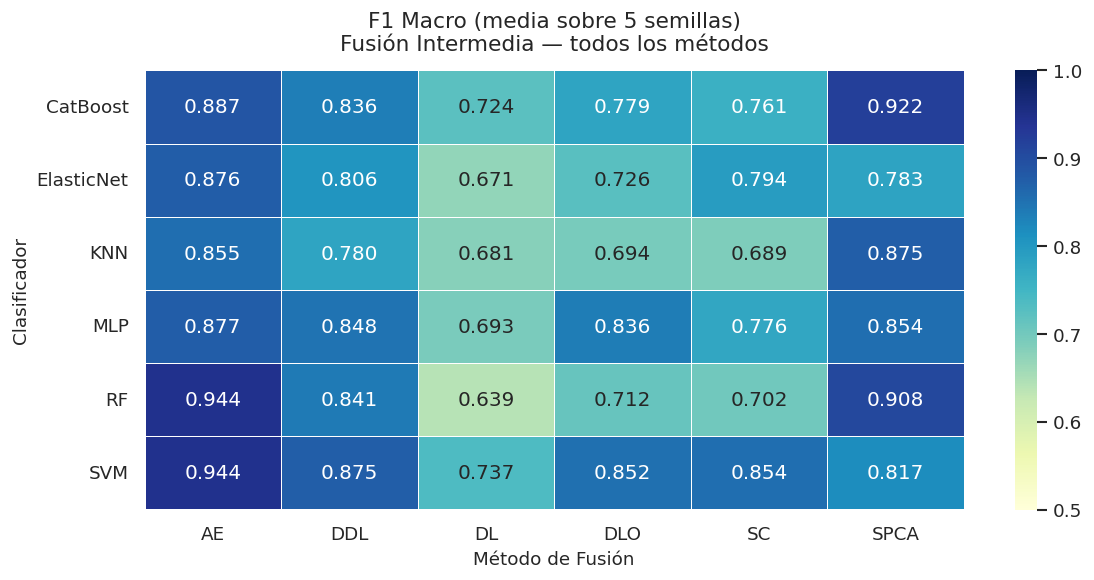

In [3]:
# ── Heatmap: F1 macro (media) por método × clasificador ──────────────────────
pivot_f1 = ranking.pivot(index='Modelo', columns='Metodo', values='F1_mean')

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(pivot_f1, annot=True, fmt='.3f', cmap='YlGnBu',
            linewidths=0.5, ax=ax, vmin=0.5, vmax=1.0)
ax.set_title('F1 Macro (media sobre 5 semillas)\nFusión Intermedia — todos los métodos',
             fontsize=13, pad=12)
ax.set_xlabel('Método de Fusión', fontsize=11)
ax.set_ylabel('Clasificador', fontsize=11)
plt.tight_layout()
plt.savefig('heatmap_f1_metodos.png', dpi=150)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# ══════════════════════════════════════════════════════════════════════
# GLOBAL BOXPLOT: CLASSIFIERS COMPARISON (CV VS TEST ACCURACY)
# ══════════════════════════════════════════════════════════════════════

# 1. Map color per algorithm
ALGORITMOS   = ['ElasticNet', 'KNN', 'SVM', 'RF', 'CatBoost', 'MLP']
base_palette = sns.color_palette('tab10', n_colors=len(ALGORITMOS))
color_map = {algo: base_palette[i] for i, algo in enumerate(ALGORITMOS)}

# 2. Transform to long format
df_melted = df_resultados.melt(
    id_vars=['Modelo'],
    value_vars=['CV_Acc', 'Test_Acc'],
    var_name='Metric',
    value_name='Accuracy'
)
df_melted['Metric'] = df_melted['Metric'].replace({'CV_Acc': 'CV', 'Test_Acc': 'Test'})

# 3. Create plot
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=df_melted,
    x='Modelo',
    y='Accuracy',
    hue='Metric',
    order=ALGORITMOS,
    hue_order=['CV', 'Test'],
    palette={'CV': 'gray', 'Test': 'gray'}, # Base layout
    width=0.6,
    ax=ax
)

# 4. Customize patches: Apply model-specific color and differentiate CV vs Test
boxes = [patch for patch in ax.patches if type(patch).__name__ == 'PathPatch']
boxes = sorted(boxes, key=lambda p: p.get_extents().xmin) # Left-to-right order

for idx, patch in enumerate(boxes):
    modelo_idx = idx // 2
    modelo_nombre = ALGORITMOS[modelo_idx]
    color = color_map[modelo_nombre]
    
    es_test = (idx % 2 != 0)
    
    if es_test:
        patch.set_facecolor(color)
        patch.set_alpha(0.55)
        patch.set_hatch('//')
    else:
        patch.set_facecolor(color)
        patch.set_alpha(1.0)

# 5. Formatting (English labels)
#ax.axhline(0.5, color='gray', linestyle=':', lw=1.2, label='Chance (0.50)')
ax.set_ylim(0.4, 1.05)
ax.set_title('Global Classifier Performance Across Latent Representations', fontsize=12, pad=12)
ax.set_xlabel('Classification Algorithm', fontsize=11)
ax.set_ylabel('Accuracy', fontsize=11)
ax.grid(axis='y', alpha=0.3, color='gray', linestyle='--')
ax.set_axisbelow(True)
ax.tick_params(axis='x', labelsize=10, rotation=30)

# 6. Legends
# Legend 1: Metric style (CV vs Test)
legend_metricas = [
    Patch(facecolor='gray', alpha=1.0, label='CV (Solid)'),
    Patch(facecolor='gray', alpha=0.55, hatch='//', label='Test (Hatched)')
]
leg1 = ax.legend(
    handles=legend_metricas,
    title='Metric',
    loc='lower right',
    bbox_to_anchor=(1.0, 0),
    ncol=1
)
ax.add_artist(leg1)



plt.tight_layout()
plt.savefig('03_global_classifier_comparison.png', dpi=300, bbox_inches='tight')
print('  ✅ Fig saved: Global classifier comparison (CV vs Test)')

## 2. Mejor clasificador por método — comparación directa

Mejor clasificador por método:
Metodo   Modelo  F1_mean   F1_std  Acc_mean  Acc_std
    AE      SVM  0.94424 0.039280   0.94442 0.039280
  SPCA CatBoost  0.92186 0.063680   0.92220 0.063346
   DDL      SVM  0.87496 0.047586   0.87776 0.046482
    SC      SVM  0.85418 0.063833   0.85554 0.063328
   DLO      SVM  0.85230 0.067739   0.85554 0.063328
    DL      SVM  0.73706 0.038164   0.74444 0.030453


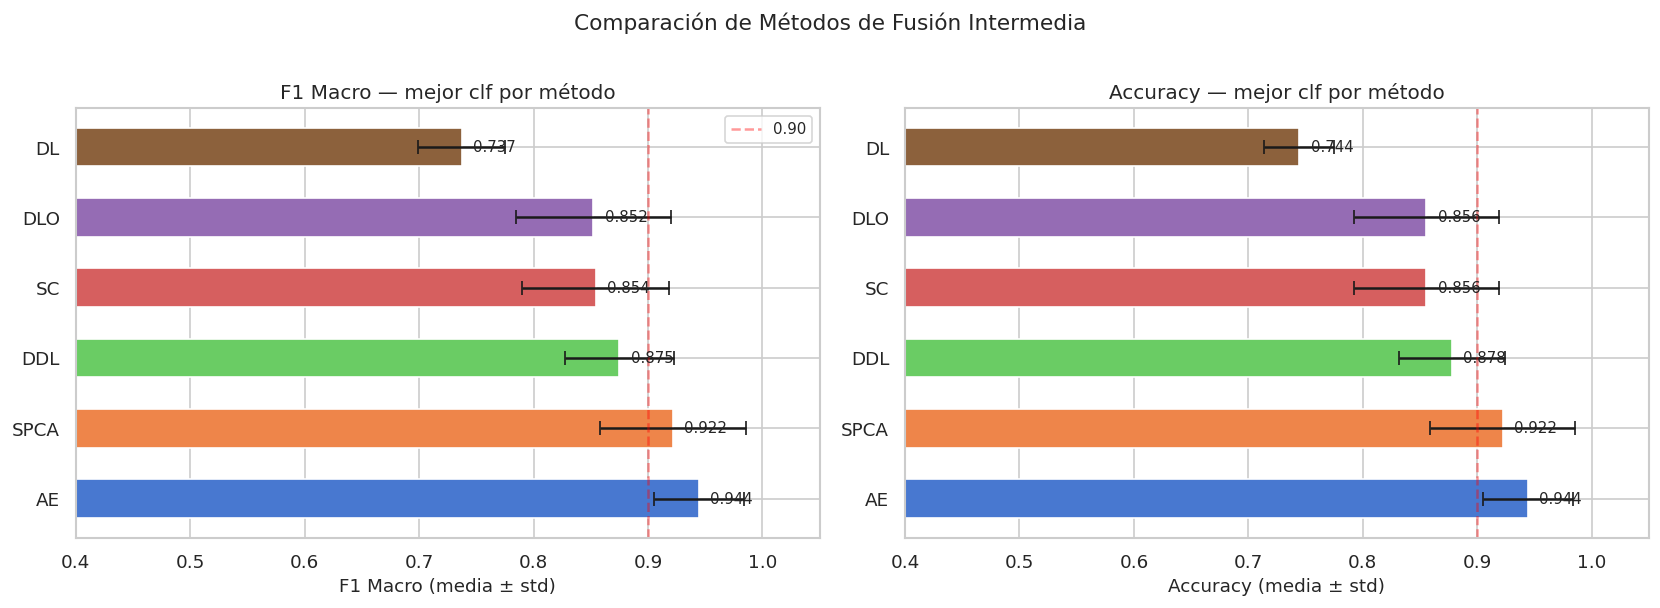

In [4]:
# Mejor F1 por método (máximo sobre clasificadores)
best_per_method = (ranking.sort_values('F1_mean', ascending=False)
                   .groupby('Metodo').first().reset_index()
                   .sort_values('F1_mean', ascending=False))

print('Mejor clasificador por método:')
print(best_per_method[['Metodo','Modelo','F1_mean','F1_std',
                        'Acc_mean','Acc_std']].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = sns.color_palette('muted', len(best_per_method))

# F1 macro
ax = axes[0]
bars = ax.barh(best_per_method['Metodo'], best_per_method['F1_mean'],
               xerr=best_per_method['F1_std'], color=colors,
               error_kw=dict(capsize=4), height=0.55)
ax.set_xlim(0.4, 1.05)
ax.set_xlabel('F1 Macro (media ± std)', fontsize=11)
ax.set_title('F1 Macro — mejor clf por método', fontsize=12)
ax.axvline(0.9, color='red', linestyle='--', alpha=0.4, label='0.90')
for bar, val in zip(bars, best_per_method['F1_mean']):
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=9)
ax.legend(fontsize=9)

# Accuracy
ax = axes[1]
bars = ax.barh(best_per_method['Metodo'], best_per_method['Acc_mean'],
               xerr=best_per_method['Acc_std'], color=colors,
               error_kw=dict(capsize=4), height=0.55)
ax.set_xlim(0.4, 1.05)
ax.set_xlabel('Accuracy (media ± std)', fontsize=11)
ax.set_title('Accuracy — mejor clf por método', fontsize=12)
ax.axvline(0.9, color='red', linestyle='--', alpha=0.4)
for bar, val in zip(bars, best_per_method['Acc_mean']):
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=9)

plt.suptitle('Comparación de Métodos de Fusión Intermedia', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('comparacion_metodos_bestclf.png', dpi=150)
plt.show()

## 3. Varianza entre semillas — estabilidad por método

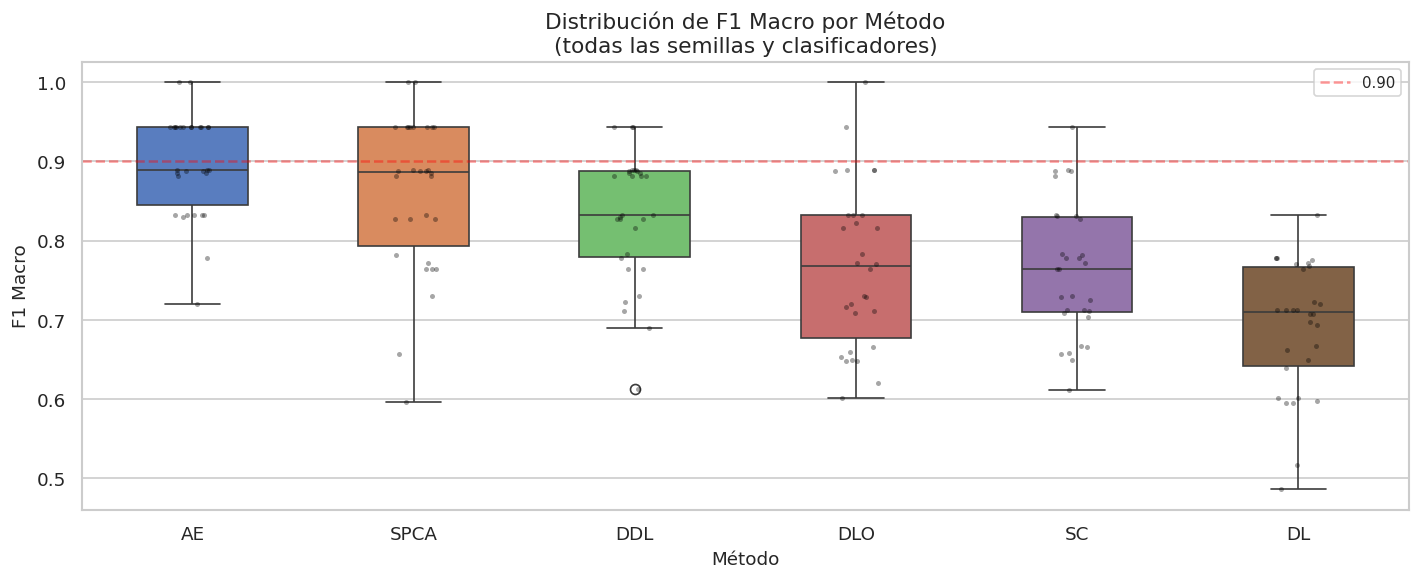

In [5]:
# Boxplot F1 por método — muestra distribución real sobre semillas y clasificadores
fig, ax = plt.subplots(figsize=(12, 5))
order = (df_all.groupby('Metodo')['F1'].mean()
         .sort_values(ascending=False).index.tolist())

sns.boxplot(data=df_all, x='Metodo', y='F1', order=order,
            palette='muted', width=0.5, ax=ax)
sns.stripplot(data=df_all, x='Metodo', y='F1', order=order,
              color='black', alpha=0.35, size=3, jitter=True, ax=ax)

ax.set_title('Distribución de F1 Macro por Método\n(todas las semillas y clasificadores)',
             fontsize=13)
ax.set_xlabel('Método', fontsize=11)
ax.set_ylabel('F1 Macro', fontsize=11)
ax.axhline(0.9, color='red', linestyle='--', alpha=0.4, label='0.90')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('boxplot_f1_metodos.png', dpi=150)
plt.show()

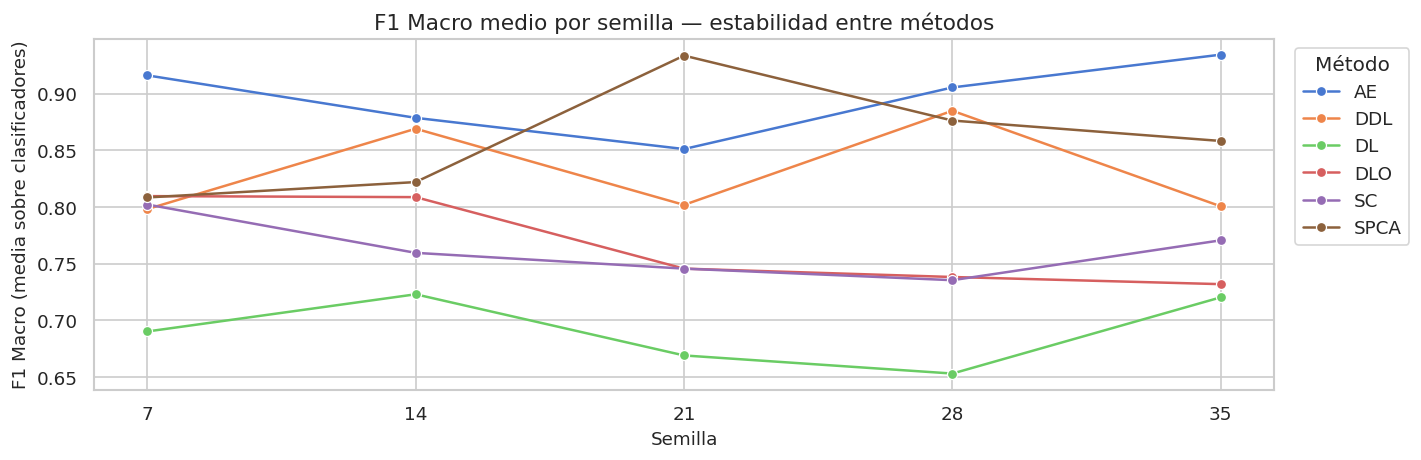

In [6]:
# Varianza por semilla — ¿qué métodos son más estables?
seed_var = (df_all.groupby(['Metodo', 'Seed'])['F1']
            .mean().reset_index()
            .rename(columns={'F1': 'F1_seed_mean'}))

fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(data=seed_var, x='Seed', y='F1_seed_mean',
             hue='Metodo', marker='o', ax=ax)
ax.set_title('F1 Macro medio por semilla — estabilidad entre métodos', fontsize=13)
ax.set_xlabel('Semilla', fontsize=11)
ax.set_ylabel('F1 Macro (media sobre clasificadores)', fontsize=11)
ax.set_xticks(df_all['Seed'].unique())
ax.legend(title='Método', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig('lineplot_f1_semillas.png', dpi=150)
plt.show()

## 4. Gap CV vs Test — sobreajuste

Gap CV - Test (positivo = sobreajuste en CV):
Metodo  CV_mean  Test_mean       Gap
    DL 0.739687   0.703707  0.035980
    SC 0.745237   0.766667 -0.021430
   DLO 0.740473   0.777777 -0.037303
  SPCA 0.799983   0.862953 -0.062970
    AE 0.830933   0.898127 -0.067193
   DDL 0.725397   0.835177 -0.109780


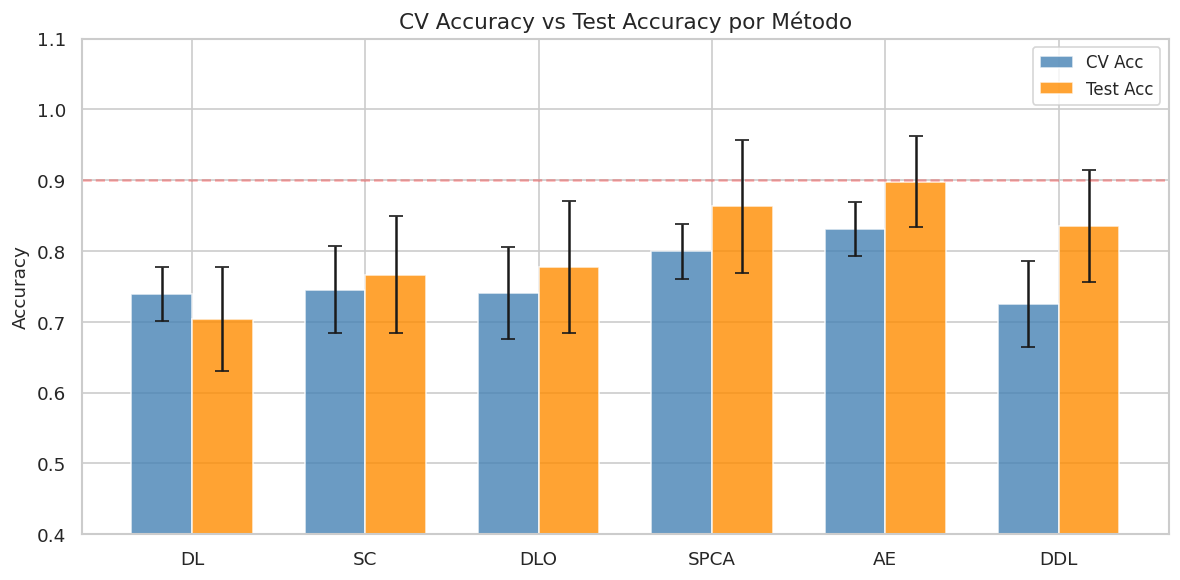

In [7]:
# CV Acc vs Test Acc por método — detectar sobreajuste
gap_stats = (df_all.groupby('Metodo')
             .agg(CV_mean=('CV_Acc','mean'), CV_std=('CV_Acc','std'),
                  Test_mean=('Test_Acc','mean'), Test_std=('Test_Acc','std'))
             .reset_index())
gap_stats['Gap'] = gap_stats['CV_mean'] - gap_stats['Test_mean']
gap_stats = gap_stats.sort_values('Gap', ascending=False)

print('Gap CV - Test (positivo = sobreajuste en CV):')
print(gap_stats[['Metodo','CV_mean','Test_mean','Gap']].to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(gap_stats))
w = 0.35
ax.bar(x - w/2, gap_stats['CV_mean'], w, label='CV Acc',
       yerr=gap_stats['CV_std'], capsize=4, color='steelblue', alpha=0.8)
ax.bar(x + w/2, gap_stats['Test_mean'], w, label='Test Acc',
       yerr=gap_stats['Test_std'], capsize=4, color='darkorange', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(gap_stats['Metodo'])
ax.set_ylim(0.4, 1.1)
ax.set_ylabel('Accuracy', fontsize=11)
ax.set_title('CV Accuracy vs Test Accuracy por Método', fontsize=13)
ax.legend(fontsize=10)
ax.axhline(0.9, color='red', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('gap_cv_test.png', dpi=150)
plt.show()

## 5. Impacto de k (número de features seleccionadas)

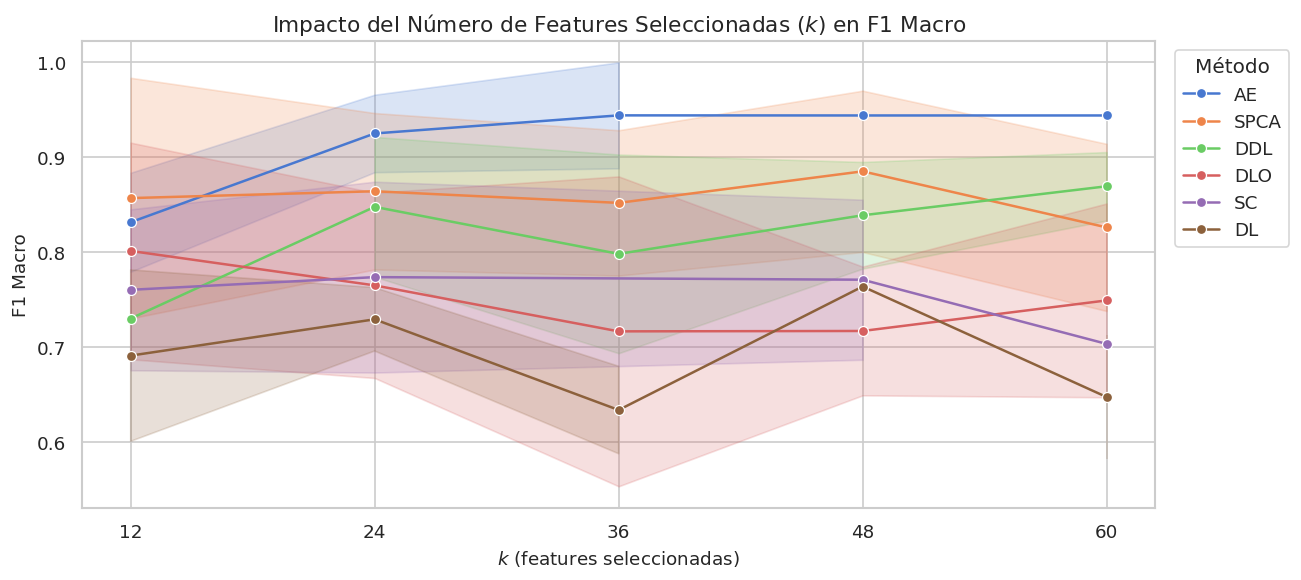

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
order_methods = (df_all.groupby('Metodo')['F1'].mean()
                 .sort_values(ascending=False).index.tolist())

sns.lineplot(data=df_all, x='k', y='F1',
             hue='Metodo', hue_order=order_methods,
             marker='o', errorbar='sd', ax=ax)
ax.set_title('Impacto del Número de Features Seleccionadas ($k$) en F1 Macro',
             fontsize=13)
ax.set_xlabel('$k$ (features seleccionadas)', fontsize=11)
ax.set_ylabel('F1 Macro', fontsize=11)
ax.set_xticks(sorted(df_all['k'].dropna().unique()))
ax.legend(title='Método', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig('impacto_k_f1.png', dpi=150)
plt.show()

## 6. Impacto de latent_dim

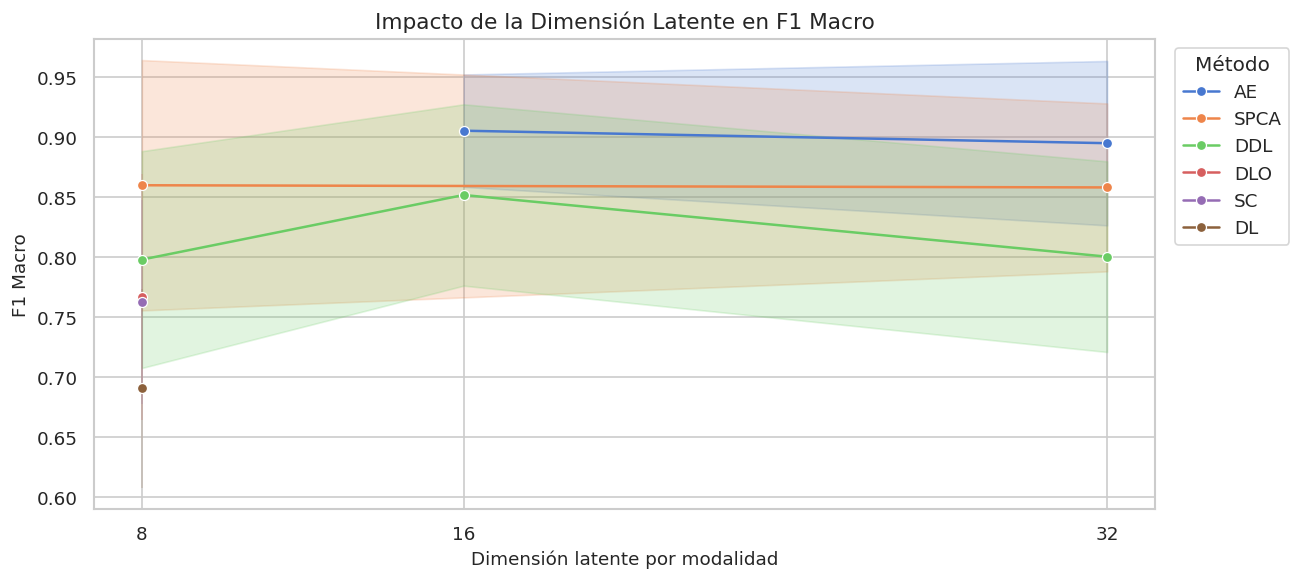

In [9]:
if 'latent_dim' in df_all.columns:
    fig, ax = plt.subplots(figsize=(11, 5))
    sns.lineplot(data=df_all, x='latent_dim', y='F1',
                 hue='Metodo', hue_order=order_methods,
                 marker='o', errorbar='sd', ax=ax)
    ax.set_title('Impacto de la Dimensión Latente en F1 Macro', fontsize=13)
    ax.set_xlabel('Dimensión latente por modalidad', fontsize=11)
    ax.set_ylabel('F1 Macro', fontsize=11)
    ax.set_xticks(sorted(df_all['latent_dim'].dropna().unique()))
    ax.legend(title='Método', bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig('impacto_latentdim_f1.png', dpi=150)
    plt.show()
else:
    print('Columna latent_dim no encontrada — omitiendo análisis.')

## 7. Selector ganador por método

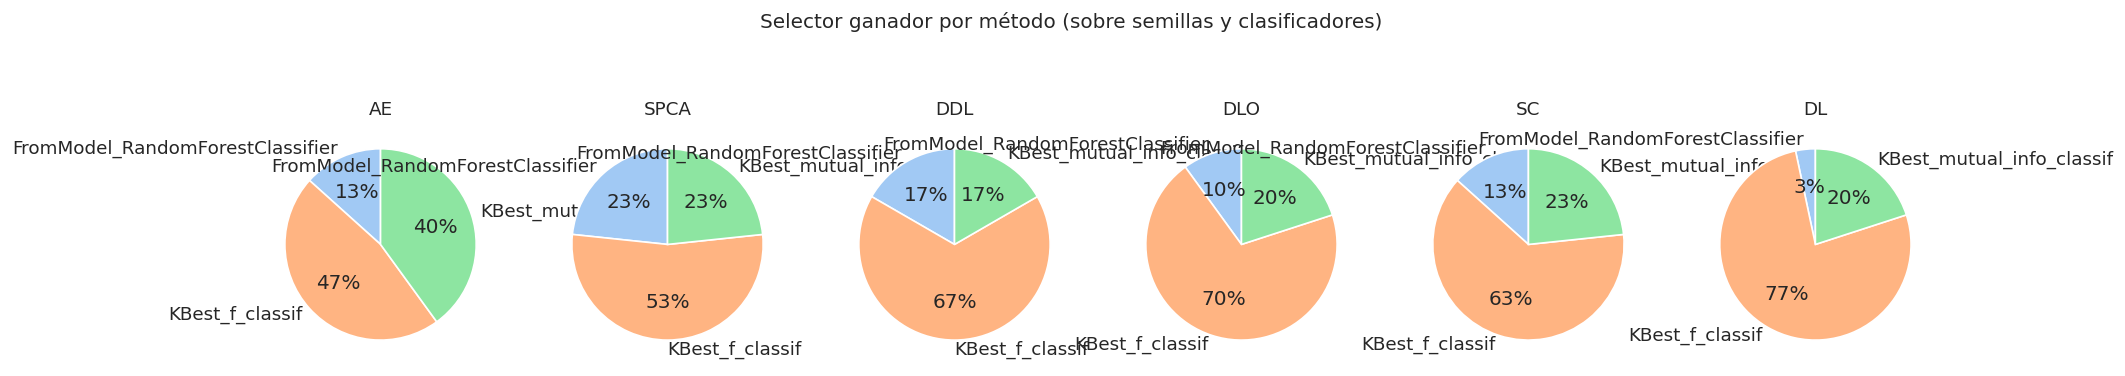

In [10]:
if 'Selector' in df_all.columns:
    sel_counts = (df_all.groupby(['Metodo', 'Selector'])
                  .size().reset_index(name='Count'))

    fig, axes = plt.subplots(1, len(dfs), figsize=(3*len(dfs), 4), sharey=False)
    if len(dfs) == 1:
        axes = [axes]
    for ax, method in zip(axes, order_methods):
        sub = sel_counts[sel_counts['Metodo'] == method]
        if sub.empty:
            continue
        ax.pie(sub['Count'], labels=sub['Selector'],
               autopct='%1.0f%%', startangle=90,
               colors=sns.color_palette('pastel'))
        ax.set_title(method, fontsize=11)
    plt.suptitle('Selector ganador por método (sobre semillas y clasificadores)',
                 fontsize=12)
    plt.tight_layout()
    plt.savefig('pie_selectores.png', dpi=150)
    plt.show()
else:
    print('Columna Selector no encontrada.')

## 8. Métricas por clase (CN / DCL / EA)

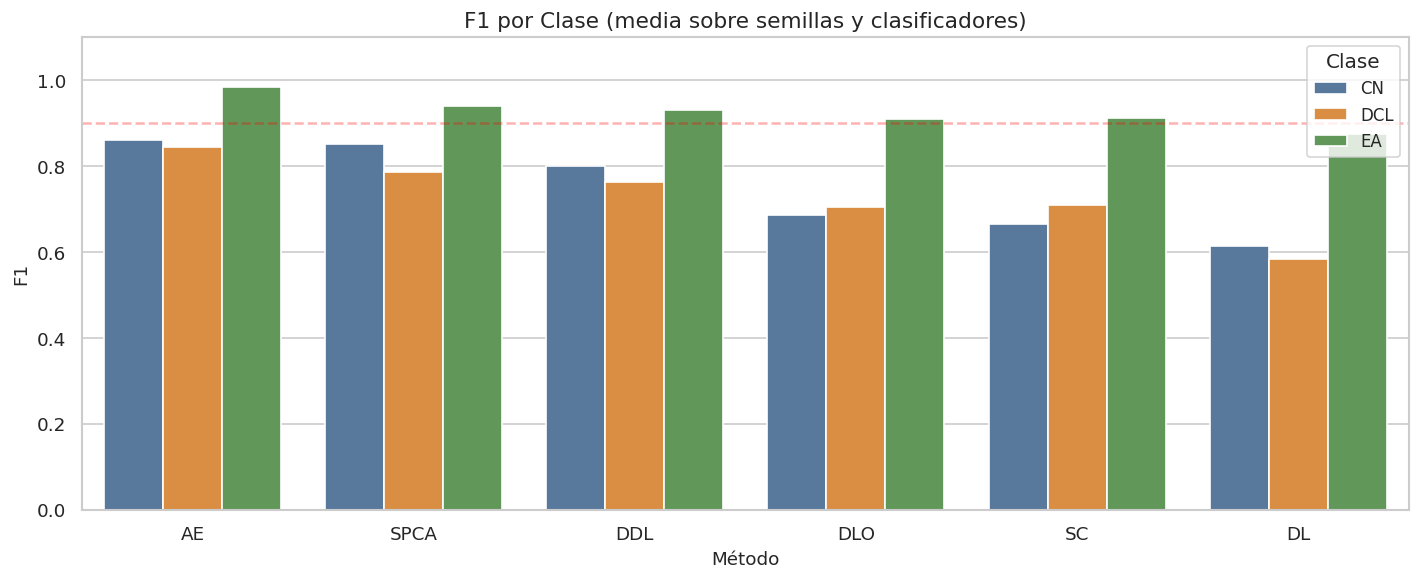

         F1_CN  F1_DCL   F1_EA  Prec_CN  Prec_DCL  Prec_EA  Recall_CN  Recall_DCL  Recall_EA
Metodo                                                                                      
AE      0.8615  0.8448  0.9852   0.8169    0.9106   0.9905     0.9167      0.7944     0.9833
DDL     0.8010  0.7622  0.9293   0.7873    0.8536   0.9000     0.8278      0.7111     0.9667
DL      0.6138  0.5842  0.8747   0.6336    0.6681   0.8309     0.6167      0.5556     0.9389
DLO     0.6865  0.7036  0.9099   0.7557    0.7516   0.8977     0.6833      0.7167     0.9333
SC      0.6657  0.7098  0.9122   0.6945    0.7375   0.8961     0.6556      0.7056     0.9389
SPCA    0.8522  0.7865  0.9403   0.8240    0.8446   0.9329     0.8889      0.7444     0.9555


In [11]:
CLASS_NAMES = ['CN', 'DCL', 'EA']
per_class_cols = [f'F1_{c}' for c in CLASS_NAMES]

if all(c in df_all.columns for c in per_class_cols):
    pc_mean = (df_all.groupby('Metodo')[per_class_cols]
               .mean().reset_index()
               .melt(id_vars='Metodo', var_name='Clase', value_name='F1_mean'))
    pc_mean['Clase'] = pc_mean['Clase'].str.replace('F1_', '')

    fig, ax = plt.subplots(figsize=(12, 5))
    sns.barplot(data=pc_mean, x='Metodo', y='F1_mean', hue='Clase',
                order=order_methods, palette=['#4e79a7','#f28e2b','#59a14f'],
                ax=ax)
    ax.set_title('F1 por Clase (media sobre semillas y clasificadores)', fontsize=13)
    ax.set_xlabel('Método', fontsize=11)
    ax.set_ylabel('F1', fontsize=11)
    ax.set_ylim(0, 1.1)
    ax.legend(title='Clase', fontsize=10)
    ax.axhline(0.9, color='red', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig('f1_por_clase.png', dpi=150)
    plt.show()

    # Tabla detallada
    pc_table = (df_all.groupby('Metodo')[per_class_cols +
                [f'Prec_{c}' for c in CLASS_NAMES] +
                [f'Recall_{c}' for c in CLASS_NAMES]]
                .mean().round(4))
    print(pc_table.to_string())
else:
    print('Columnas por clase no encontradas — ')
    print('Estas columnas requieren la versión actualizada del script de búsqueda.')
    print('Disponible en los resultados de la segunda búsqueda (dlo/spca/sc).')

## 9. Importancia de features latentes por método

In [12]:
# Cargar todos los archivos de importancia de todas las carpetas
all_imp = []
for method, folder in METHOD_DIRS.items():
    pattern = os.path.join(folder, 'importancia_ROIs_*.csv')
    for fpath in glob.glob(pattern):
        fname = os.path.basename(fpath)
        parts = fname.replace('.csv','').split('_')
        # formato: importancia_ROIs_{method}_{clf}_s{seed}.csv
        try:
            clf_name = parts[3]
            seed_val = parts[4]
        except:
            clf_name = 'unknown'
            seed_val = 'unknown'
        tmp = pd.read_csv(fpath)
        tmp['Metodo']   = method
        tmp['Modelo']   = clf_name
        tmp['Semilla']  = seed_val
        # Normalizar 0-1 por archivo
        mn, mx = tmp['Importancia'].min(), tmp['Importancia'].max()
        tmp['Imp_Norm'] = (tmp['Importancia'] - mn) / (mx - mn + 1e-9)
        all_imp.append(tmp)

if all_imp:
    df_imp = pd.concat(all_imp, ignore_index=True)
    print(f'Archivos de importancia cargados: {len(all_imp)}')
    print(f'Features únicas: {df_imp["ROI"].nunique()}')
else:
    print('No se encontraron archivos de importancia. Ejecutar primero los experimentos.')
    df_imp = None

Archivos de importancia cargados: 180
Features únicas: 96


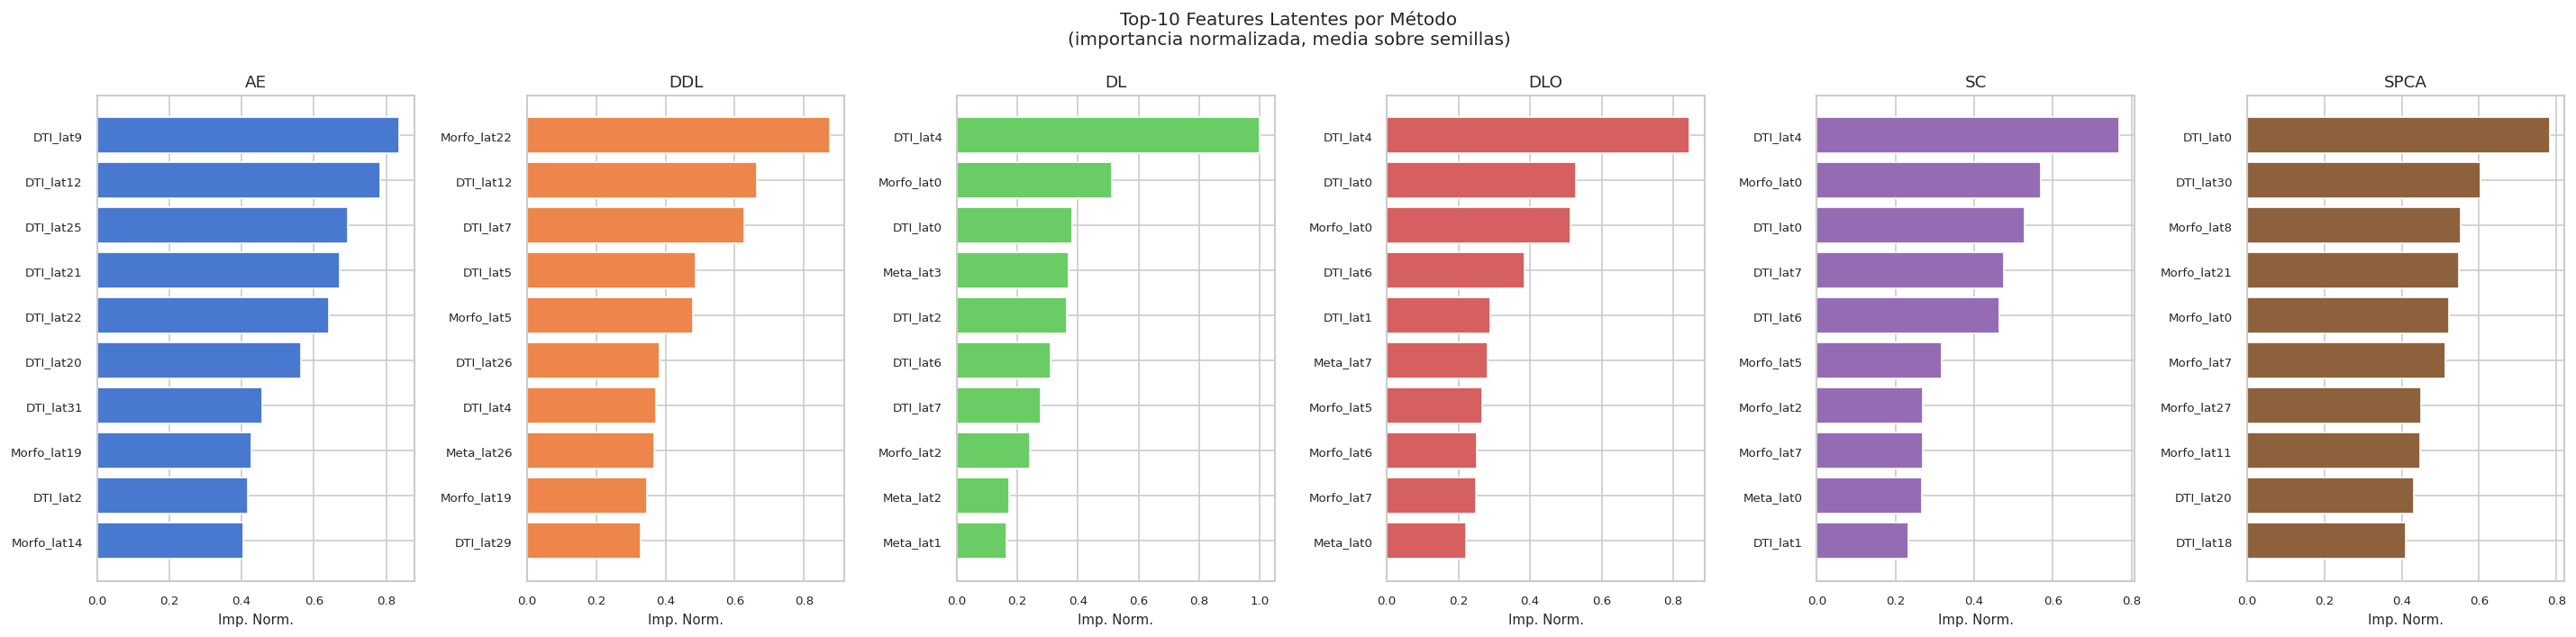

In [13]:
# Top-10 features más importantes por método
if df_imp is not None:
    top_per_method = (df_imp.groupby(['Metodo', 'ROI'])['Imp_Norm']
                      .mean().reset_index()
                      .sort_values(['Metodo', 'Imp_Norm'], ascending=[True, False]))

    n_methods = len(top_per_method['Metodo'].unique())
    fig, axes = plt.subplots(1, n_methods,
                              figsize=(4 * n_methods, 6), sharey=False)
    if n_methods == 1:
        axes = [axes]

    for ax, method in zip(axes, top_per_method['Metodo'].unique()):
        sub = top_per_method[top_per_method['Metodo'] == method].head(10)
        ax.barh(sub['ROI'], sub['Imp_Norm'],
                color=sns.color_palette('muted')[list(
                    top_per_method['Metodo'].unique()).index(method)])
        ax.set_title(method, fontsize=11)
        ax.set_xlabel('Imp. Norm.', fontsize=9)
        ax.invert_yaxis()
        ax.tick_params(labelsize=8)

    plt.suptitle('Top-10 Features Latentes por Método\n(importancia normalizada, media sobre semillas)',
                 fontsize=12)
    plt.tight_layout()
    plt.savefig('top10_features_latentes.png', dpi=150)
    plt.show()

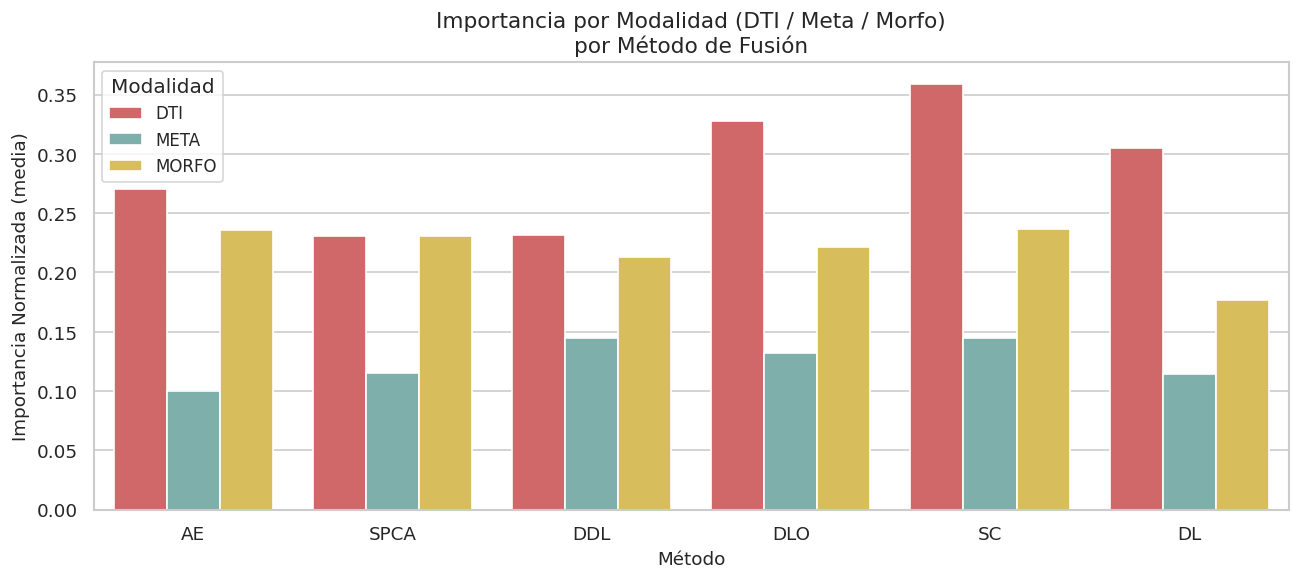

In [14]:
# ── Importancia por modalidad ─────────────────────────────────────────────────
# Las features latentes tienen el formato '{MOD}_lat{i}' — extraer modalidad
if df_imp is not None and df_imp['ROI'].str.contains('_lat').any():
    df_imp['Modalidad'] = df_imp['ROI'].str.split('_lat').str[0].str.upper()

    mod_imp = (df_imp.groupby(['Metodo', 'Modalidad'])['Imp_Norm']
               .mean().reset_index())

    fig, ax = plt.subplots(figsize=(11, 5))
    sns.barplot(data=mod_imp, x='Metodo', y='Imp_Norm', hue='Modalidad',
                order=order_methods,
                palette=['#e15759','#76b7b2','#edc948'], ax=ax)
    ax.set_title('Importancia por Modalidad (DTI / Meta / Morfo)\npor Método de Fusión',
                 fontsize=13)
    ax.set_xlabel('Método', fontsize=11)
    ax.set_ylabel('Importancia Normalizada (media)', fontsize=11)
    ax.legend(title='Modalidad', fontsize=10)
    plt.tight_layout()
    plt.savefig('importancia_por_modalidad.png', dpi=150)
    plt.show()
else:
    print('ROI names no siguen el formato {mod}_lat{i} — omitiendo análisis de modalidad.')

## 10. Tabla resumen final para tesis

In [15]:
# Tabla con mejor clf por método: F1, Acc, Prec, Recall ± std
tabla_tesis = []
for method in order_methods:
    if method not in dfs:
        continue
    sub = dfs[method]
    best_clf = sub.groupby('Modelo')['F1'].mean().idxmax()
    rows = sub[sub['Modelo'] == best_clf]
    tabla_tesis.append({
        'Método':        method,
        'Clasificador':  best_clf,
        'Accuracy':      f"{rows['Test_Acc'].mean():.4f} ± {rows['Test_Acc'].std():.4f}",
        'Precision':     f"{rows['Precision'].mean():.4f} ± {rows['Precision'].std():.4f}",
        'Recall':        f"{rows['Recall'].mean():.4f} ± {rows['Recall'].std():.4f}",
        'F1 macro':      f"{rows['F1'].mean():.4f} ± {rows['F1'].std():.4f}",
        'latent_dim':    int(rows['latent_dim'].mode().iloc[0]) if 'latent_dim' in rows else 'N/A',
        'recon_error':   f"{rows['recon_error'].mean():.4f}" if 'recon_error' in rows else 'N/A',
    })

tabla_df = pd.DataFrame(tabla_tesis)
print(tabla_df.to_string(index=False))
tabla_df.to_csv('tabla_resumen_fusión_intermedia.csv', index=False)
print('\nGuardado: tabla_resumen_fusión_intermedia.csv')

Método Clasificador        Accuracy       Precision          Recall        F1 macro  latent_dim recon_error
    AE          SVM 0.9444 ± 0.0393 0.9492 ± 0.0395 0.9444 ± 0.0393 0.9442 ± 0.0393          32      0.0693
  SPCA     CatBoost 0.9222 ± 0.0633 0.9264 ± 0.0632 0.9222 ± 0.0633 0.9219 ± 0.0637           8      0.1434
   DDL          SVM 0.8778 ± 0.0465 0.8845 ± 0.0507 0.8778 ± 0.0465 0.8750 ± 0.0476          16      0.0629
   DLO          SVM 0.8555 ± 0.0633 0.8583 ± 0.0666 0.8555 ± 0.0633 0.8523 ± 0.0677           8      0.2235
    SC          SVM 0.8555 ± 0.0633 0.8575 ± 0.0661 0.8555 ± 0.0633 0.8542 ± 0.0638           8      0.1930
    DL          SVM 0.7444 ± 0.0305 0.7620 ± 0.0354 0.7444 ± 0.0305 0.7371 ± 0.0382           8      0.2290

Guardado: tabla_resumen_fusión_intermedia.csv
